# 2. Data Cleaning
---
**Objective:** Remove or correct impossible, corrupted and incosistent values in the training and test sets, and derive calendar features from the purchase date, so that the merge and imputation stage (next notebook) starts from reliable base.

**Approach:** Every rule is applied to the training and test files with the same logic. Rows are only removed from the training set; no test row is ever dropped. Each sted reads the file produced by the previous one:

| Section | Action | Output file (train / test) |
|---|---|---|
| 2.1 | Drop training rows without `Total a Pagar`; set invalid negative values to `NaN` | `train_2.csv` / `test_2.csv` |
| 2.2 | Separate identifiers, target, numeric and categorical features | – (no file written) |
| 2.3 | Structural missing values: `is_first_purchase` flag and sentinel imputation | `*_2_3.csv` |
| 2.4 | Consistency corrections (`prior_mean_purchase_value`, `spend_365d`, `prior_max_purchase_value`) | `*_2_4_1.csv`, `*_2_4_2.csv`, `*_2_4_3.csv` |
| 2.5 | Calendar features, removal of `purchase_date`, exploratory analysis | `*_2_5.csv`, `*_2_5_1.csv` |
| 2.6 | Final audit of residual missing values | – (no file written) |


---

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
trainFile = "../../../data/trainDataset/train.csv"
testFile = "../../../data/testDataset/test.csv"

df = pd.read_csv(trainFile)
df_test = pd.read_csv(testFile)

## 2.1. Removing Records with Missing `Total a Pagar`

Training rows with no value for `Total a Pagar` (the invoice total) lack the main monetary attribute of the transaction and are treated as corrupted records. Imputing a monetary amount would mean inventing it, and the affected share is small (verified below), so these rows are dropped. Only this column is used as criterion. The test set is not filtered, so that every test record is kept.

In [3]:
outputFile = "../../../data/trainDataset/train_2.csv"
outputFile_test = "../../../data/testDataset/test_2.csv"

df_clean = df.dropna(subset=['Total a Pagar']).copy()

df_clean.to_csv(outputFile, index=False)


print(f"Dataset cleaned saved successfully to: {outputFile}")


Dataset cleaned saved successfully to: ../../../data/trainDataset/train_2.csv


### 2.1.1. Verification of the Row Removal
We confirm that no `NaN` remains in `Total a Pagar` and compute of removed rows from the difference in dataset length.

In [4]:
# Verify directly if there are still null values in that column (should return 0)
print("NA Values in 'Total a Pagar':", df_clean['Total a Pagar'].isnull().sum())

# Dynamic calculation: rows before, after, and total removed
removed_rows_count = len(df) - len(df_clean)
print(f"Rows before: {len(df)} | Rows after: {len(df_clean)} | Removed rows: {removed_rows_count}")

NA Values in 'Total a Pagar': 0
Rows before: 6534 | Rows after: 6469 | Removed rows: 65


**Conclusion:** 65 rows were removed (6,534 → 6,469), about 1.0% of the training set. Every remaining training transaction now has a `Total a Pagar` value, so later statistics and models are based on complete transaction totals. Because the loss is small, the effect on the training distribution should be negligible.

### 2.1.2. Invalid Negative Values
The exploratory analysis in *Section 1.4* found negative values in four features whose business definition only allows values ≥ 0: `days_since_previous_purchase`, `prior_mean_purchase_value`, `prior_mean_gap_days` and `spend_365d`. The true value cannot be recovered at this point, so the negatives are replaced by  `NaN` in both train and test (instead of dropping rows or clipping to 0). they are then treated together with the other missing values: the three purchase-history features in Section 2.3, and `spend_365d` in the final audit (Section 2.6).

In [5]:
non_negative = [
    "days_since_previous_purchase", 
    "prior_mean_purchase_value", 
    "prior_mean_gap_days", 
    "spend_365d"
]

# Convert negative values in these columns to NaN
df_clean[non_negative] = df_clean[non_negative].mask(df_clean[non_negative] < 0)
df_test[non_negative] = df_test[non_negative].mask(df_test[non_negative] < 0)

# Save the cleaned datasets
df_clean.to_csv(outputFile, index=False)
df_test.to_csv(outputFile_test, index=False)

print(f"Dataset cleaned saved successfully to: {outputFile}")
print(f"Test dataset cleaned saved successfully to: {outputFile_test}")

Dataset cleaned saved successfully to: ../../../data/trainDataset/train_2.csv
Test dataset cleaned saved successfully to: ../../../data/testDataset/test_2.csv


To validate this step, we count the remaining missing values (`NaN`) and negative values in the four features. The `NaN` counts include both the genuinely missing values already present in the raw data and the negatives that were just masked.

In [6]:
# Columns that must be non-negative according to business rules
non_negative = [
    "days_since_previous_purchase", 
    "prior_mean_purchase_value", 
    "prior_mean_gap_days", 
    "spend_365d"
]

# Validation table: missing values (NaN) and remaining negative values
def summarize_validation(df_clean, non_negative):
    summary = pd.DataFrame({
        'Total NaNs': df_clean[non_negative].isna().sum(),
        'NaNs Percentage (%)': (df_clean[non_negative].isna().mean() * 100).round(2),
        'Remaining negative values (< 0)': (df_clean[non_negative] < 0).sum()
    })
    return summary

validation_summary = summarize_validation(df_clean, non_negative)
validation_summary_test = summarize_validation(df_test, non_negative)

print("=== CONFIRMATION OF NULL AND NEGATIVE VALUES IN DF_CLEAN ===")
print(validation_summary)
print("\n=== CONFIRMATION OF NULL AND NEGATIVE VALUES IN DF_CLEAN_TEST ===")
print(validation_summary_test)


=== CONFIRMATION OF NULL AND NEGATIVE VALUES IN DF_CLEAN ===
                              Total NaNs  NaNs Percentage (%)  \
days_since_previous_purchase         812                12.55   
prior_mean_purchase_value            813                12.57   
prior_mean_gap_days                 1259                19.46   
spend_365d                           210                 3.25   

                              Remaining negative values (< 0)  
days_since_previous_purchase                                0  
prior_mean_purchase_value                                   0  
prior_mean_gap_days                                         0  
spend_365d                                                  0  

=== CONFIRMATION OF NULL AND NEGATIVE VALUES IN DF_CLEAN_TEST ===
                              Total NaNs  NaNs Percentage (%)  \
days_since_previous_purchase          54                 5.48   
prior_mean_purchase_value             54                 5.48   
prior_mean_gap_days            

**Conclusion:** No negative values remain in either dataset. The share of missing values in the three pruchase-history features is clearly higher in train (12.6%, 12.6% and 19.5%) than in test (5.5%, 5.5% and 7.9%), whereas `spend_365d` is similar (3.25% in both). This difference between train and test should be kept in mind when evaluating generalisation.

____________________________________________________________________________________________________________________________________________________________________________________

## 2.2. Feature Type Selection

Before the remaining cleaning steps, the columns are classified into groups so that each later step is applied to the right kind of variable:

1. **Identifiers and dates (`ID`, `costumer_id`, `purchase_date`):** not predictors. Unique keys carry no generalisable information and would let a model memorise individual records (*overfitting*). `purchase_date` is kept for now because the calendar features are derived from it in Section 2.5, and it is dropped in Section 2.5.1.
2. **Target (`repeat_purchase_90d`):** kept apart from the predictors. It is not present in the test file, which is why test has one column less than train.
3. **Numeric features:** all remaining  columns with a numeric dtype (spend metrics, purchase counts, time gaps).
4. **Categorical features:** all remaining non-numeric columns (e.g. payment type, salesperson, transport method, warehouse).

The split is automatic (based on dtype). It describes the dataset at this stage only: columns created later (such as `is_first_purchase` and the temporal features) are not included, so the lists must be recomputed before encoding and scaling.

In [7]:
# Identifiers and dates that MUST NOT be used for model training
identifiers = ["ID", "customer_id", "purchase_date"]
target = "repeat_purchase_90d"

# Automatic separation between numerical and categorical variables
def get_numeric_categorical(df, identifiers, target):
    numeric = [
        c for c in df.columns 
        if c not in identifiers + [target] and pd.api.types.is_numeric_dtype(df[c])
    ]
    
    categorical = [
        c for c in df.columns 
        if c not in identifiers + [target] + numeric
    ]
    
    return numeric, categorical

numeric_train, categorical_train = get_numeric_categorical(df_clean, identifiers, target)
numeric_test, categorical_test = get_numeric_categorical(df_test, identifiers, target)

# Validation output
print(f"Total features (Train): {df_clean.shape[1]} | Numeric: {len(numeric_train)} | Categorical: {len(categorical_train)}")
print(f"Total features (Test): {df_test.shape[1]} | Numeric: {len(numeric_test)} | Categorical: {len(categorical_test)}")

Total features (Train): 39 | Numeric: 29 | Categorical: 6
Total features (Test): 38 | Numeric: 29 | Categorical: 6


**Conclusion:** Train has 29 numeric and 6 categorical features, and test has the same split. Together with the 3 identifiers and the target, this accounts for all 39 train columns (38 in test, without the target). Keeping identifiers out of the feature matrix prevents the model from memorising individual records.

____________________________________________________________________________________________________________________________________________________________________________________

## 2.3. Handling Structural Missing Values (MNAR)

Missingness in the purchase-history features is largely **structural** (Missing Not At Random): for a costumer's first purchase there is no history to summarise. `prior_mean_gap_days` needs at least two earlier purchases, which is why it has more missing values (19.5% in train) than `days_since_previous_purchase` (12.6%).

**Strategy:**
* Create the binary flag `is_first_purchase` = 1 when `days_since_previous_purchase` is missing.
* Fill `prior_mean_gap_days`, `prior_std_gap_days` and `prior_std_purchase_value` with **0**.
* Fill `days_since_previous_purchase`, `prior_mean_purchase_value`, `prior_min_purchase_value` and `prior_max_purchase_value` with **−1**, a value outside the valid domain that the model can tell apart from real values.

**Caveat:** the flag is derived from `days_since_previous_purchase`, so it also marks rows where that value was an invalid negative converted to `NaN` in Section 2.1.2.

In [8]:
inputFileTrain = "../../../data/trainDataset/train_2.csv"
inputFileTest = "../../../data/testDataset/test_2.csv"
outputFileTrain = "../../../data/trainDataset/train_2_3.csv"
outputFileTest = "../../../data/testDataset/test_2_3.csv"


def process_missing_values(input_file, output_file, dataset_label="Dataset"):
  # Carregar dataset
  df_clean = pd.read_csv(input_file)

  # Create a binary flag for new customers (First Purchase)
  df_clean['is_first_purchase'] = (
      df_clean['days_since_previous_purchase'].isnull().astype(int)
  )

  # Zero imputation for variation/deviation/mean columns that depend on multiple purchases
  zero_impute_cols = [
      'prior_std_purchase_value',
      'prior_std_gap_days',
      'prior_mean_gap_days',
  ]
  df_clean[zero_impute_cols] = df_clean[zero_impute_cols].fillna(0)

  # Indicator value imputation (-1) for time counts and averages of new customers
  indicator_impute_cols = [
      'days_since_previous_purchase',
      'prior_mean_purchase_value',
      'prior_min_purchase_value',
      'prior_max_purchase_value',
  ]
  df_clean[indicator_impute_cols] = df_clean[indicator_impute_cols].fillna(-1)

  # Save processed file
  df_clean.to_csv(output_file, index=False)
 
  # Print validation messages
  print(f"=== Processing {dataset_label} ===")
  print(f"Dataset read from: {input_file}")
  print(f"Dataset saved successfully to: {output_file}")

  # Validation of New Customer Flag and Imputations
  new_customers = df_clean['is_first_purchase'].sum()
  print(
      f"[2] Flag 'is_first_purchase': {new_customers} new customers identified"
      f" ({(new_customers/len(df_clean))*100:.1f}%)"
  )

  minus_one_counts = (df_clean[indicator_impute_cols] == -1).sum().to_dict()
  print(f"-> -1 Valuing applied per column: {minus_one_counts}\n")

  return df_clean


# Run processing for both Train and Test datasets
df_train_clean = process_missing_values(
    inputFileTrain, outputFileTrain, dataset_label="Train"
)
df_test_clean = process_missing_values(
    inputFileTest, outputFileTest, dataset_label="Test"
)


=== Processing Train ===
Dataset read from: ../../../data/trainDataset/train_2.csv
Dataset saved successfully to: ../../../data/trainDataset/train_2_3.csv
[2] Flag 'is_first_purchase': 812 new customers identified (12.6%)
-> -1 Valuing applied per column: {'days_since_previous_purchase': 812, 'prior_mean_purchase_value': 813, 'prior_min_purchase_value': 603, 'prior_max_purchase_value': 603}

=== Processing Test ===
Dataset read from: ../../../data/testDataset/test_2.csv
Dataset saved successfully to: ../../../data/testDataset/test_2_3.csv
[2] Flag 'is_first_purchase': 54 new customers identified (5.5%)
-> -1 Valuing applied per column: {'days_since_previous_purchase': 54, 'prior_mean_purchase_value': 54, 'prior_min_purchase_value': 22, 'prior_max_purchase_value': 22}



**Conclusion:** Since the missing values are structural, naive imputation (mean or median) would hide th efact that these costumers have no history. The `is_first_purchase` flag keeps that information (812 train rows, 12.6%; 54 test rows, 5.5%), and the constants (-1 and 0) keep these rows in the dataset without distorting the distribution of real customers. Tree-based models can use the flag and the sentinel values to separate first-time buyers from returning customers.

### 2.3.1. Seasonality Check: Monthly Transaction Volume
Before extracting calendar features (Section 2.5), we check wether the number of transactions changes across the year. The plot uses the original train and test files.

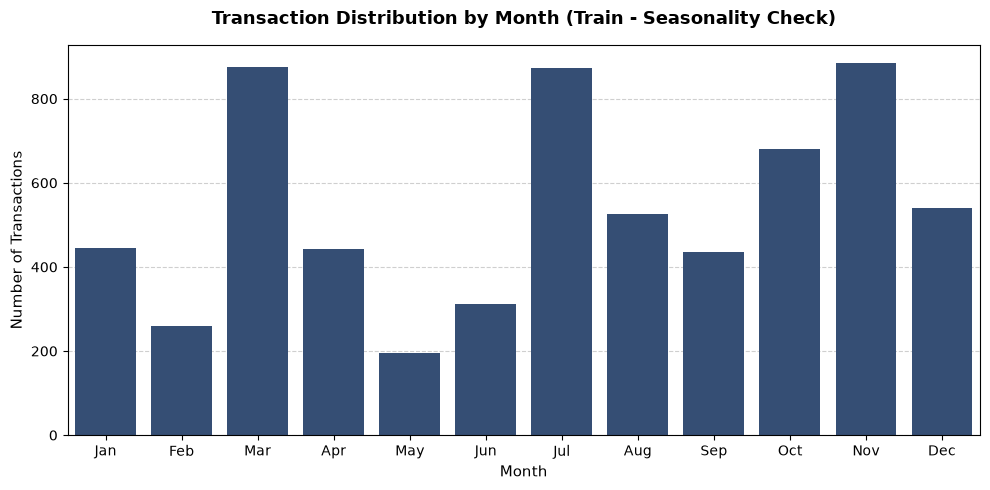

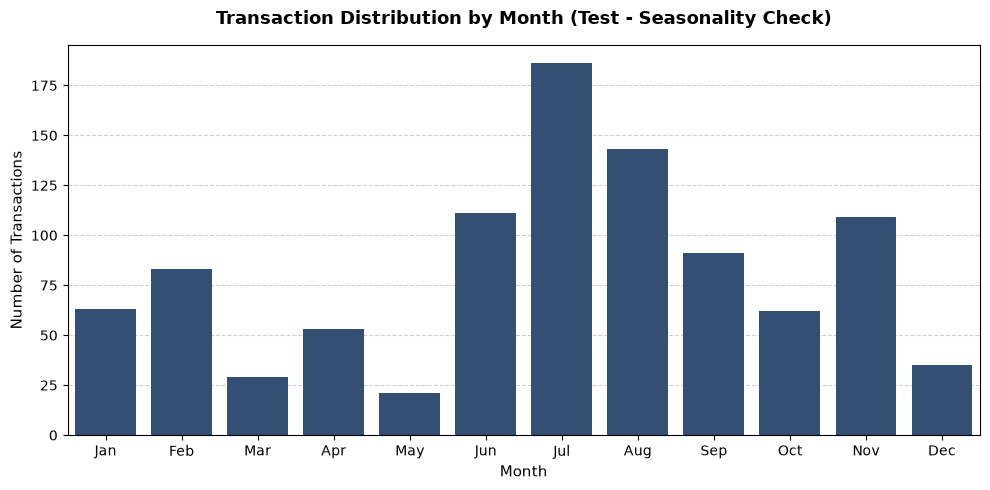

In [9]:
def plot_monthly_distribution(dataframe, dataset_label="Train"):
  # Ensure purchase_date is datetime for plotting
  df_temp_plot = dataframe.dropna(subset=["purchase_date"]).copy()
  df_temp_plot["purchase_date"] = pd.to_datetime(
      df_temp_plot["purchase_date"]
  )

  # Extract month name or number for histogram grouping
  df_temp_plot["month_name"] = df_temp_plot["purchase_date"].dt.strftime("%b")
  month_order = [
      "Jan",
      "Feb",
      "Mar",
      "Apr",
      "May",
      "Jun",
      "Jul",
      "Aug",
      "Sep",
      "Oct",
      "Nov",
      "Dec",
  ]

  # Plotting the histogram / countplot
  plt.figure(figsize=(10, 5))
  sns.countplot(
      data=df_temp_plot,
      x="month_name",
      order=month_order,
      color="#2b4c7e",
      zorder=2,
  )

  plt.title(
      f"Transaction Distribution by Month ({dataset_label} - Seasonality"
      " Check)",
      fontsize=13,
      fontweight="bold",
      pad=15,
  )
  plt.xlabel("Month", fontsize=11)
  plt.ylabel("Number of Transactions", fontsize=11)
  plt.grid(axis="y", linestyle="--", alpha=0.6)
  plt.tight_layout()

  plt.show()


# Run for Train and Test
plot_monthly_distribution(df, dataset_label="Train")
plot_monthly_distribution(df_test, dataset_label="Test")


**Conclusion:**
* **Train:** transaction volume is clearly seasonal. March, July and November have the highest volumes (about 875–885 transactions each), October is also high (about 680), and the lowest are May (about 195), February (about 260) and June (about 310).
* **Test:** the pattern is different. July is the peak (about 185), followed by August, June and November (110-145), while March (about 30), May (about 20) and December (about 35) are the lowest.
* **Reading:** July and November are high and May is low in both sets, but march is a peak in rain and one of the weakest months in test. Month therefore matters for volume, but the seasonal pattern is not stable between train and test. `purchase_month` and `purchase_quarter` can still be created, but their usefulness should be confirmed through model validation instead of being assumed from this plot.

____________________________________________________________________________________________________________________________________________________________________________________

## 2.4. Inconsistency Values 
In this section, columns are cross-checked against each other using business rules (for example, a mean must equal total spend divided by purchase count, and a single purchase cannot exceed total spend). Values that violate these rules are corrected.

### 2.4.1.`prior_mean_purchase_value` 
The stored value is compared with the recalculated mean ($\text{prior\_total\_spend} / \text{prior\_purchase\_count}$) for customers with at least one prior purchase. Where they differ by more than a small tolerance ($10^{-4}$), the stored value is replaced by the recalculated one. Rows without purcahse bistory keep the sentinel value from Section 2.3.

In [10]:

inputFileTrain = "../../../data/trainDataset/train_2_3.csv"
outputFileTrain = "../../../data/trainDataset/train_2_4_1.csv"

inputFileTest = "../../../data/testDataset/test_2_3.csv"
outputFileTest = "../../../data/testDataset/test_2_4_1.csv"


def correct_prior_mean_purchase_value(
    input_file, output_file, dataset_label="Dataset"
):
  # 1. Load dataset
  df = pd.read_csv(input_file)

  # 2. Safely calculate the mean purchase value (avoiding division by zero)
  # If prior_purchase_count is 0 or NaN, keep NaN/indicator value (-1)
  calculated_mean = np.where(
      (df["prior_purchase_count"] > 0) & (df["prior_total_spend"].notna()),
      df["prior_total_spend"] / df["prior_purchase_count"],
      df[
          "prior_mean_purchase_value"
      ],  # Keep existing value (e.g., -1 for first purchases)
  )

  # 3. Identify mismatches using a small tolerance (1e-4) to account for floating-point rounding
  mismatch_mask = (df["prior_purchase_count"] > 0) & (
      ~np.isclose(
          df["prior_mean_purchase_value"],
          calculated_mean,
          atol=1e-4,
          equal_nan=True,
      )
  )

  # 4. Count and replace the mismatched cells with the calculated value
  mismatches_count = mismatch_mask.sum()

  df.loc[mismatch_mask, "prior_mean_purchase_value"] = calculated_mean[
      mismatch_mask
  ]

  # 5. Save the updated dataset
  df.to_csv(output_file, index=False)

  print(f"=== Processing {dataset_label} ===")
  print(f"Correction complete!")
  print(f"• Total cells updated: {mismatches_count}")
  print(f"• Dataset read from: {input_file}")
  print(f"• Dataset saved successfully to: {output_file}\n")

  return df


# Run the correction for Train and Test
df_train_clean = correct_prior_mean_purchase_value(
    inputFileTrain, outputFileTrain, dataset_label="Train"
)
df_test_clean = correct_prior_mean_purchase_value(
    inputFileTest, outputFileTest, dataset_label="Test"
)


=== Processing Train ===
Correction complete!
• Total cells updated: 272
• Dataset read from: ../../../data/trainDataset/train_2_3.csv
• Dataset saved successfully to: ../../../data/trainDataset/train_2_4_1.csv

=== Processing Test ===
Correction complete!
• Total cells updated: 41
• Dataset read from: ../../../data/testDataset/test_2_3.csv
• Dataset saved successfully to: ../../../data/testDataset/test_2_4_1.csv



#### Summary of Correction Results
* **Cells corrected:** 272 in train (about 4.2% of rows) and 41 in test.
* **Likely origin:** this count may include rows that were set to the sentinel −1 in Section 2.3 because of an invalid negative value (Section 2.1.2). Those rows have a purchase history, so they fail this consistency check and are now recovered.
* **Assumption:** the recalculation is only correct if `prior_total_spend` and `prior_purchase_count` are themselves reliable.
* **Outcome:** `prior_mean_purchase_value` is now consistent with its components in both datasets.


### 2.4.2.`spend_365d`
Some records contain placeholder or impossible values. The rules are: annuall spend cannot exceed the lifetime spend (`prior_total_spend`), and it must be 0 if there were no purchases in the last 365 days. Affected values are rebuilt from related columns:
* **No purchase in the last 365 days** (`purchase_count_365d == 0`): `spend_365d = 0`.
* **All prior purchases in the last year** (`purchase_count_365d == prior_purchase_count`): `spend_365d = prior_total_spend`.
* **Otherwise:** `spend_365d` is *estimated* as `purchase_count_365d × prior_mean_purchase_value`, limited to the range [`spend_180d`, `prior_total_spend`].

In [11]:
# 1. Define input and output file paths
inputFileTrain = "../../../data/trainDataset/train_2_4_1.csv"
outputFileTrain = "../../../data/trainDataset/train_2_4_2.csv"

inputFileTest = "../../../data/testDataset/test_2_4_1.csv"
outputFileTest = "../../../data/testDataset/test_2_4_2.csv"


def correct_spend_365d(input_file, output_file, dataset_label="Dataset"):
  # Load dataset from previous stage
  df_clean = pd.read_csv(input_file)

  # Count initial corrupted entries before correction
  corrupted_before = (df_clean['spend_365d'] >= 1e8).sum()

  # 2. Define logical function to reconstruct the exact value of spend_365d
  def recalculate_spend_365d(row):
    # Check for data corruption or domain inconsistency
    if row['spend_365d'] >= 1e8 or row['spend_365d'] > row['prior_total_spend']:
      # Case 1: No purchases in the last year
      if row['purchase_count_365d'] == 0:
        return 0.0
      # Case 2: All historical purchases occurred within the last year
      elif row['purchase_count_365d'] == row['prior_purchase_count']:
        return row['prior_total_spend']
      # Case 3: Partial activity in the last year
      else:
        estimated = (
            row['purchase_count_365d'] * row['prior_mean_purchase_value']
        )
        # Respect logical business bounds: [spend_180d <= spend_365d <= prior_total_spend]
        estimated = min(estimated, row['prior_total_spend'])
        estimated = max(estimated, row['spend_180d'])
        return estimated
    return row['spend_365d']

  # 3. Apply the correction to the DataFrame
  df_clean['spend_365d'] = df_clean.apply(recalculate_spend_365d, axis=1)

  # 4. Save updated dataset to the output path
  df_clean.to_csv(output_file, index=False)

  # Count remaining corrupted entries after correction
  corrupted_after = (df_clean['spend_365d'] >= 1e8).sum()

  # Execution confirmation
  print(f"=== Processing {dataset_label} ===")
  print("Correction complete!")
  print(f"• Corrupted entries detected initially: {corrupted_before}")
  print(f"• Corrupted entries remaining in 'spend_365d': {corrupted_after}")
  print(f"• Dataset read from: {input_file}")
  print(f"• Dataset successfully saved to: {output_file}\n")

  return df_clean


# Execute correction for both Train and Test datasets
df_train_clean = correct_spend_365d(
    inputFileTrain, outputFileTrain, dataset_label="Train"
)
df_test_clean = correct_spend_365d(
    inputFileTest, outputFileTest, dataset_label="Test"
)


=== Processing Train ===
Correction complete!
• Corrupted entries detected initially: 15
• Corrupted entries remaining in 'spend_365d': 0
• Dataset read from: ../../../data/trainDataset/train_2_4_1.csv
• Dataset successfully saved to: ../../../data/trainDataset/train_2_4_2.csv

=== Processing Test ===
Correction complete!
• Corrupted entries detected initially: 2
• Corrupted entries remaining in 'spend_365d': 0
• Dataset read from: ../../../data/testDataset/test_2_4_1.csv
• Dataset successfully saved to: ../../../data/testDataset/test_2_4_2.csv



#### Summary of Correction Results
* **Placeholders:** 15 train records and 2 test records contained a dummy value of 1,000,000,000 €. After the correction, none remain.
* **Scope of the rule:** the code also overwrites values larger than `prior_total_spend`. The notebook does not report how many such cases there were.
* **Accuracy:** the first two cases are exact, while the third is an estimate.
* **Not covered:** missing values (`NaN`, including those from Section 2.1.2) are not changed by this rule, because comparisons with `NaN` are false. They remain in the data (210 train rows, 32 test rows) and are dealt with after the audit in Section 2.6.



### 2.4.3.` In `prior_max_purchase_value`
A single purchase cannot be larger than the total spent: $V_{\max} \le S_{\text{total}}$.

In [12]:
# 1. Define input and output file paths
inputFileTrain = "../../../data/trainDataset/train_2_4_2.csv"
outputFileTrain = "../../../data/trainDataset/train_2_4_3.csv"

inputFileTest = "../../../data/testDataset/test_2_4_2.csv"
outputFileTest = "../../../data/testDataset/test_2_4_3.csv"


def process_max_purchase_value(
    input_file, output_file, dataset_label="Dataset"
):
  # Load dataset from previous stage
  df_clean = pd.read_csv(input_file)

  # Count initial inflated entries before correction
  inflated_before = (
      df_clean['prior_max_purchase_value']
      > df_clean['prior_total_spend'] + 1e-4
  ).sum()

  # 2. Define logical function to correct prior_max_purchase_value
  def correct_max_purchase_value(row):
    # Check if max purchase value exceeds total spend
    if row['prior_max_purchase_value'] > row['prior_total_spend'] + 1e-4:
      # Case 1: Single transaction history -> Max equals Total
      if row['prior_purchase_count'] == 1:
        return row['prior_total_spend']
      # Case 2: Multiple transactions -> Cap max at prior_total_spend
      else:
        # Max possible spend for a single order given the min spend
        max_possible = row['prior_total_spend'] - (
            (row['prior_purchase_count'] - 1) * row['prior_min_purchase_value']
        )
        return max(
            row['prior_min_purchase_value'],
            min(row['prior_total_spend'], max_possible),
        )
    return row['prior_max_purchase_value']

  # 3. Apply the correction to the DataFrame
  df_clean['prior_max_purchase_value'] = df_clean.apply(
      correct_max_purchase_value, axis=1
  )

  # 4. Save updated dataset to the output path
  df_clean.to_csv(output_file, index=False)

  # Count remaining inflated entries after correction
  inflated_after = (
      df_clean['prior_max_purchase_value']
      > df_clean['prior_total_spend'] + 1e-4
  ).sum()

  # Execution confirmation
  print(f"=== Processing {dataset_label} ===")
  print("Correction complete!")
  print(f"• Inflated entries detected initially: {inflated_before}")
  print(
      "• Inflated entries remaining in 'prior_max_purchase_value':"
      f" {inflated_after}"
  )
  print(f"• Dataset read from: {input_file}")
  print(f"• Dataset successfully saved to: {output_file}\n")

  return df_clean


# Execute correction for both Train and Test datasets
df_train_clean = process_max_purchase_value(
    inputFileTrain, outputFileTrain, dataset_label="Train"
)
df_test_clean = process_max_purchase_value(
    inputFileTest, outputFileTest, dataset_label="Test"
)


=== Processing Train ===
Correction complete!
• Inflated entries detected initially: 45
• Inflated entries remaining in 'prior_max_purchase_value': 0
• Dataset read from: ../../../data/trainDataset/train_2_4_2.csv
• Dataset successfully saved to: ../../../data/trainDataset/train_2_4_3.csv

=== Processing Test ===
Correction complete!
• Inflated entries detected initially: 6
• Inflated entries remaining in 'prior_max_purchase_value': 0
• Dataset read from: ../../../data/testDataset/test_2_4_2.csv
• Dataset successfully saved to: ../../../data/testDataset/test_2_4_3.csv



#### Summary of Correction Results
`prior_max_purchase_value` exceeded `prior_total_spend` in **45 train records** and **6 test records**. The correction is:
* **One prior purchase** (`prior_purchase_count == 1`): the maximum equals `prior_total_spend`.
* **Several prior purchases:** the maximum is set to the largest value that is still possible given the minimum, i.e. `prior_total_spend − (prior_purchase_count − 1) × prior_min_purchase_value`, limited to the range [`prior_min_purchase_value`, `prior_total_spend`].

For single-purchase customers the result is exact. For the others it is an **upper bound**, not necessarily the true maximum. No inflated values remain in either dataset.



____________________________________________________________________________________________________________________________________________________________________________________


## 2.5. Temporal Feature Extraction
The seasonality check in Section 2.3.1 shows that transaction volume varies across the year, although the pattern is not identical in train and test. The raw purchase date is therefore decomposed into calendar components that a model can use directly: `purchase_year`, `purchase_month`, `purchase_day`, `purchase_dayofweek` (0 = Monday), `purchase_quarter` and `is_weekend` (Saturday and Sunday).


In [13]:

# 1. Define input and output file paths
inputFileTrain = "../../../data/trainDataset/train_2_4_3.csv"
outputFileTrain = "../../../data/trainDataset/train_2_5.csv"

inputFileTest = "../../../data/testDataset/test_2_4_3.csv"
outputFileTest = "../../../data/testDataset/test_2_5.csv"


def extract_temporal_features(
    input_file, output_file, dataset_label="Dataset"
):
  # Load dataset from previous stage
  df_clean = pd.read_csv(input_file)

  # Ensure purchase_date is formatted as datetime
  df_clean['purchase_date'] = pd.to_datetime(df_clean['purchase_date'])

  # Extraction of cyclic and temporal attributes based on our annual monthly distribution
  df_clean['purchase_year'] = df_clean['purchase_date'].dt.year
  df_clean['purchase_month'] = df_clean['purchase_date'].dt.month
  df_clean['purchase_day'] = df_clean['purchase_date'].dt.day
  df_clean['purchase_dayofweek'] = (
      df_clean['purchase_date'].dt.dayofweek
  )  # 0=Monday, 6=Sunday
  df_clean['purchase_quarter'] = df_clean['purchase_date'].dt.quarter
  df_clean['is_weekend'] = (
      df_clean['purchase_dayofweek'].isin([5, 6]).astype(int)
  )

  # Save updated dataset to output path
  df_clean.to_csv(output_file, index=False)

  # Execution confirmation and print metrics
  temporal_cols = [
      'purchase_year',
      'purchase_month',
      'purchase_day',
      'purchase_dayofweek',
      'purchase_quarter',
      'is_weekend',
  ]
  print(f"=== Processing {dataset_label} ===")
  print(f"Dataset read from: {input_file}")
  print(f"Dataset saved successfully to: {output_file}")
  print(
      f"• New temporal attributes created ({len(temporal_cols)}):"
      f" {temporal_cols}"
  )
  print(
      "• Current dataset dimensions: "
      f"{df_clean.shape[0]} rows x {df_clean.shape[1]} columns\n"
  )

  return df_clean


# Execute extraction for both Train and Test datasets
df_train_clean = extract_temporal_features(
    inputFileTrain, outputFileTrain, dataset_label="Train"
)
df_test_clean = extract_temporal_features(
    inputFileTest, outputFileTest, dataset_label="Test"
)


=== Processing Train ===
Dataset read from: ../../../data/trainDataset/train_2_4_3.csv
Dataset saved successfully to: ../../../data/trainDataset/train_2_5.csv
• New temporal attributes created (6): ['purchase_year', 'purchase_month', 'purchase_day', 'purchase_dayofweek', 'purchase_quarter', 'is_weekend']
• Current dataset dimensions: 6469 rows x 46 columns

=== Processing Test ===
Dataset read from: ../../../data/testDataset/test_2_4_3.csv
Dataset saved successfully to: ../../../data/testDataset/test_2_5.csv
• New temporal attributes created (6): ['purchase_year', 'purchase_month', 'purchase_day', 'purchase_dayofweek', 'purchase_quarter', 'is_weekend']
• Current dataset dimensions: 986 rows x 45 columns



### 2.5.1. Removal of Raw Date Features

Once the calendar components exist, `purchase_date` is redundant. A raw date or timestamp is not directly usable by most models, and one-hot encoding it would create one column per distinct date. The column is therefore dropped from the feature space.


In [14]:
# 1. Define input and output file paths
inputFileTrain = "../../../data/trainDataset/train_2_5.csv"
outputFileTrain = "../../../data/trainDataset/train_2_5_1.csv"

inputFileTest = "../../../data/testDataset/test_2_5.csv"
outputFileTest = "../../../data/testDataset/test_2_5_1.csv"


def drop_purchase_date(input_file, output_file, dataset_label="Dataset"):
  # 2. Load dataset from the previous step
  df_clean = pd.read_csv(input_file)

  print(f"=== Processing {dataset_label} ===")

  # 3. Drop the redundant 'purchase_date' column
  if 'purchase_date' in df_clean.columns:
    df_clean = df_clean.drop(columns=['purchase_date'])
    print("Column 'purchase_date' successfully removed!")
  else:
    print("The column 'purchase_date' no longer exists in the dataset.")

  # 4. Save the updated dataset to the new CSV file
  df_clean.to_csv(output_file, index=False)

  print(f"Dataset read from: {input_file}")
  print(f"Dataset successfully saved to: {output_file}\n")

  return df_clean


# Execute column dropping for both Train and Test datasets
df_train_clean = drop_purchase_date(
    inputFileTrain, outputFileTrain, dataset_label="Train"
)
df_test_clean = drop_purchase_date(
    inputFileTest, outputFileTest, dataset_label="Test"
)


=== Processing Train ===
Column 'purchase_date' successfully removed!
Dataset read from: ../../../data/trainDataset/train_2_5.csv
Dataset successfully saved to: ../../../data/trainDataset/train_2_5_1.csv

=== Processing Test ===
Column 'purchase_date' successfully removed!
Dataset read from: ../../../data/testDataset/test_2_5.csv
Dataset successfully saved to: ../../../data/testDataset/test_2_5_1.csv



### 2.5.2. Exploratory Data Analysis of Temporal Features

#### 2.5.2.1.
We compare the number of transactions on weekdays and weekends in train and test, to validate `is_weekend` and check that both sets have a similar structure.

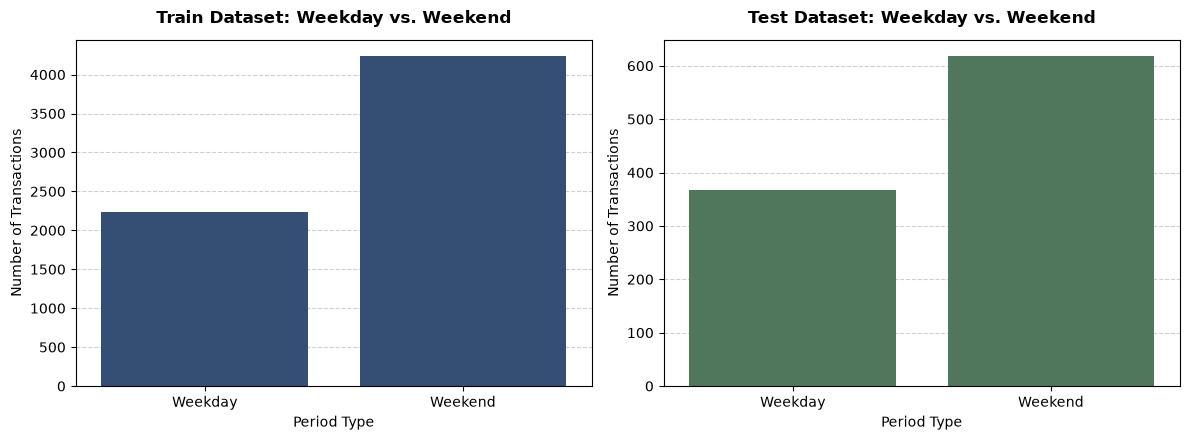

In [15]:

def plot_weekend_distribution_comparison(df_train, df_test):
  # Mapeamento para visualização
  train_plot = df_train.copy()
  train_plot['weekend_label'] = train_plot['is_weekend'].map(
      {0: 'Weekday', 1: 'Weekend'}
  )

  test_plot = df_test.copy()
  test_plot['weekend_label'] = test_plot['is_weekend'].map(
      {0: 'Weekday', 1: 'Weekend'}
  )

  fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=False)

  # Plot Treino
  ax1 = sns.countplot(
      data=train_plot,
      x='weekend_label',
      order=['Weekday', 'Weekend'],
      color='#2b4c7e',
      zorder=2,
      ax=axes[0],
  )
  ax1.set_axisbelow(True)
  axes[0].set_title(
      'Train Dataset: Weekday vs. Weekend',
      fontsize=12,
      fontweight='bold',
      pad=12,
  )
  axes[0].set_xlabel('Period Type', fontsize=10)
  axes[0].set_ylabel('Number of Transactions', fontsize=10)
  axes[0].grid(axis='y', linestyle='--', alpha=0.6, zorder=1)

  # Plot Teste
  ax2 = sns.countplot(
      data=test_plot,
      x='weekend_label',
      order=['Weekday', 'Weekend'],
      color='#4a7c59',
      zorder=2,
      ax=axes[1],
  )
  ax2.set_axisbelow(True)
  axes[1].set_title(
      'Test Dataset: Weekday vs. Weekend',
      fontsize=12,
      fontweight='bold',
      pad=12,
  )
  axes[1].set_xlabel('Period Type', fontsize=10)
  axes[1].set_ylabel('Number of Transactions', fontsize=10)
  axes[1].grid(axis='y', linestyle='--', alpha=0.6, zorder=1)

  plt.tight_layout()
  plt.show()


# Run comparison plot
plot_weekend_distribution_comparison(df_train_clean, df_test_clean)


**Conclusions:**
* **Weekend dominance:** In the train set, about 4,250 transactions (≈ 66%) take place on weekends and about 2,230 (≈ 34%) on weekdays. Weekends therefore have almost twice as many transactions as weekdays.
* **Per-day intensity:** Weekends are only 2 of the 7 days of the week, yet they concentrate about two thirds of the transactions. On average, a weekend day has roughly 4–5 times more transactions than a weekday, so the purchasing activity is strongly concentrated at the end of the week.
* **Train and test consistency:** The test set follows the same structure, with about 620 weekend transactions (≈ 63%) and about 370 weekday transactions (≈ 37%). The weekday/weekend proportion is very similar in both sets, so `is_weekend` has a comparable distribution in training and evaluation, and no distribution shift is observed for this feature.
* **Interpretation and limits:** The plot only shows *when* orders are placed, not whether customers come back. It does not show that `is_weekend` is predictive of the target. That is assessed in the next analysis, where the 90-day repeat purchase rate is compared between weekdays and weekends.

#### 2.5.2.2.
We check whether the day type of a purchase is related to the target, by comparing the 90-day repeat purchase rate (`repeat_purchase_90d`) of weekday and weekend transactions. This is shown for the train set only, because the test set has no target.

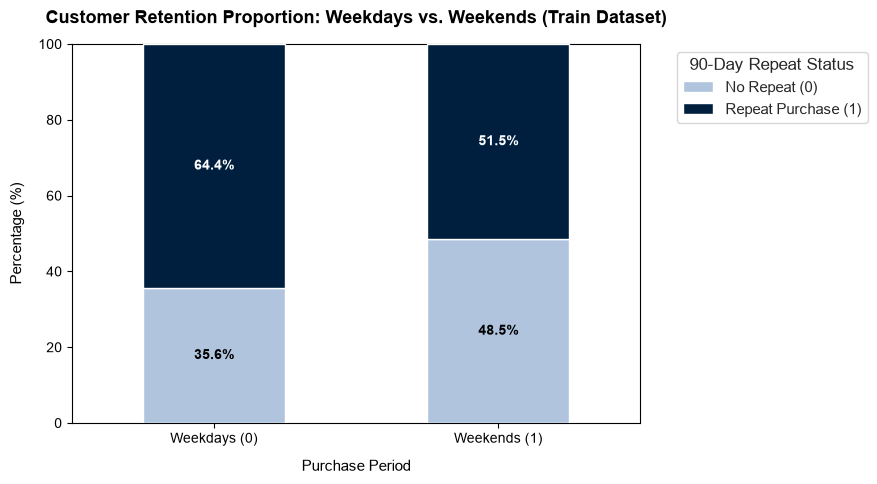

In [16]:

def plot_weekend_retention_proportion(
    dataframe, target_col='repeat_purchase_90d'
):
  # Check that the target exists before plotting
  if target_col not in dataframe.columns:
    print(
        f"Note: '{target_col}' not found in the provided dataset. Chart skipped."
    )
    return

  # Prepare data for stacked bar chart: percentage of repeat purchases by weekend vs. weekday
  ct = (
      pd.crosstab(
          dataframe['is_weekend'], dataframe[target_col], normalize='index'
      )
      * 100
  )
  ct.index = ['Weekdays (0)', 'Weekends (1)']
  ct.columns = ['No Repeat (0)', 'Repeat Purchase (1)']

  # Graphic configuration: set the chart with visible grid lines behind the bars
  fig, ax = plt.subplots(figsize=(9, 5))
  sns.set_theme(style='white')

  ax.set_axisbelow(True)
  ax.yaxis.grid(True, color='#b0b0b0', linestyle='-', linewidth=0.8, zorder=0)

  ax = ct.plot(
      kind='bar',
      stacked=True,
      ax=ax,
      color=['#b0c4de', '#001f3f'],
      width=0.5,
      zorder=3,
  )

  plt.title(
      'Customer Retention Proportion: Weekdays vs. Weekends (Train Dataset)',
      fontsize=13,
      fontweight='bold',
      pad=15,
  )
  plt.xlabel('Purchase Period', fontsize=11, labelpad=10)
  plt.ylabel('Percentage (%)', fontsize=11, labelpad=10)
  plt.xticks(rotation=0, fontsize=10)
  plt.legend(
      title='90-Day Repeat Status',
      bbox_to_anchor=(1.05, 1),
      loc='upper left',
  )
  plt.ylim(0, 100)

  # Add percentage values inside the bars
  for n, c in enumerate(ct.columns):
    for i, val in enumerate(ct[c]):
      cumulative = ct.iloc[i, :n].sum() + val / 2
      if val > 5:
        ax.text(
            i,
            cumulative,
            f'{val:.1f}%',
            ha='center',
            va='center',
            color='white' if n == 1 else 'black',
            fontweight='bold',
            fontsize=10,
            zorder=4,
        )

  plt.tight_layout()
  plt.show()


# Executar exclusivamente para o dataset de TREINO
plot_weekend_retention_proportion(df_train_clean)


**Conclusions:**
* **Repeat rate by period:** In the train set, 64.4% of the transactions made on weekdays are followed by a repeat purchase within 90 days. For weekend transactions the rate is 51.5%. Weekday transactions therefore have a repeat rate about 13 percentage points higher (roughly 25% higher in relative terms).
* **Class balance:** Both groups have a repeat rate above 50%, so repeat purchases are the majority outcome in each period. Because weekends hold about two thirds of the transactions, the overall repeat rate is around 56%, which is not strongly imbalanced.
* **Predictive relevance:** The gap between the two bars shows that the day type of a purchase is associated with the target. This supports keeping `is_weekend` as a candidate predictor. It is a simple binary feature and does not add high-cardinality noise.
* **Possible interpretation:** Weekday buyers may be more routine or professional customers who order regularly, while weekend buyers may be more occasional. This is a hypothesis that has not been tested here.
* **Limits:** The chart shows an association, not a causal effect, and it uses the train set only because the test set has no target. The difference may also be partly explained by other variables, such as customer type or first-time buyers (`is_first_purchase`). A statistical test (e.g. chi-square) would confirm that the gap is not due to chance, and the feature's real value should be confirmed during modelling.

#### 2.5.2.3. Monthly Retention Dynamics (`purchase_month`)
We check whether customer activity depends on the month of the purchase, by plotting the mean of `purchase_count_365d` (the number of purchases in the previous 365 days) for each `purchase_month`. This feature is used because it exists in both train and test, so the two sets can be compared side by side.

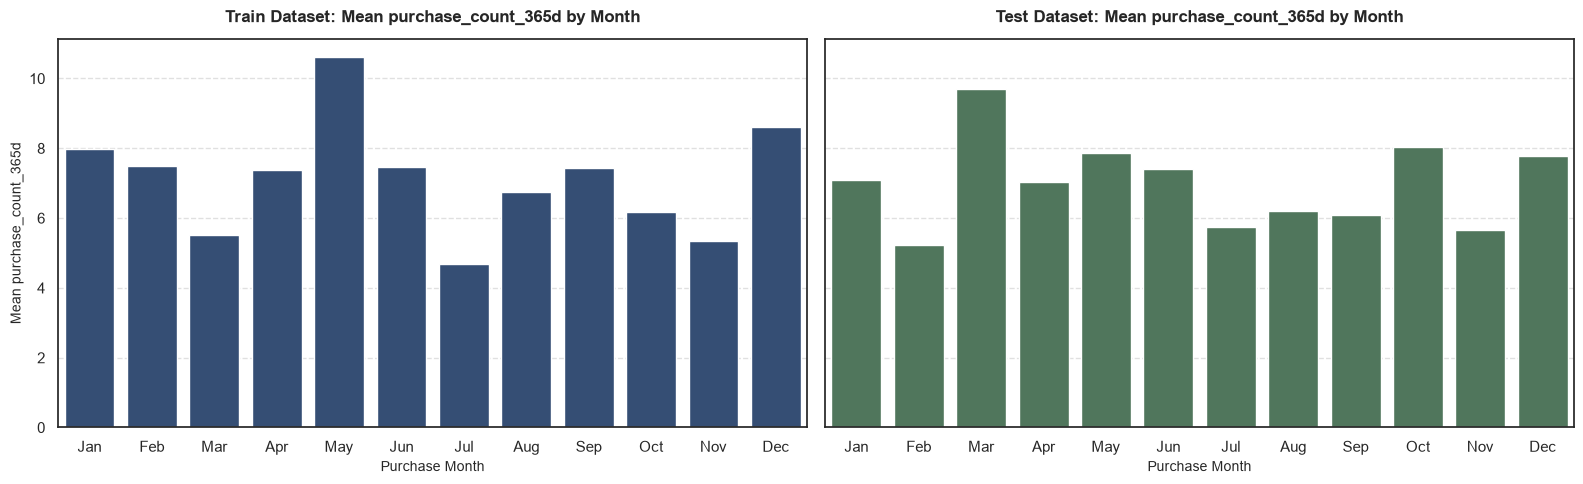

In [17]:

def plot_monthly_engagement_comparison(df_train, df_test, feature='purchase_count_365d'):
  month_map = {
      1: 'Jan', 2: 'Feb', 3: 'Mar', 4: 'Apr', 5: 'May', 6: 'Jun',
      7: 'Jul', 8: 'Aug', 9: 'Sep', 10: 'Oct', 11: 'Nov', 12: 'Dec',
  }
  month_order = [
      'Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun',
      'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec',
  ]

  # Process Train
  train_monthly = df_train.groupby('purchase_month')[feature].mean().reset_index()
  train_monthly['month_name'] = train_monthly['purchase_month'].map(month_map)

  # Process Test
  test_monthly = df_test.groupby('purchase_month')[feature].mean().reset_index()
  test_monthly['month_name'] = test_monthly['purchase_month'].map(month_map)

  fig, axes = plt.subplots(1, 2, figsize=(16, 5), sharey=True)

  # Plot Train
  sns.barplot(
      data=train_monthly,
      x='month_name',
      y=feature,
      order=month_order,
      color='#2b4c7e',
      ax=axes[0],
  )
  axes[0].set_title(
      f'Train Dataset: Mean {feature} by Month',
      fontsize=12,
      fontweight='bold',
      pad=12,
  )
  axes[0].set_xlabel('Purchase Month', fontsize=10)
  axes[0].set_ylabel(f'Mean {feature}', fontsize=10)
  axes[0].grid(axis='y', linestyle='--', alpha=0.6)

  # Plot Test
  sns.barplot(
      data=test_monthly,
      x='month_name',
      y=feature,
      order=month_order,
      color='#4a7c59',
      ax=axes[1],
  )
  axes[1].set_title(
      f'Test Dataset: Mean {feature} by Month',
      fontsize=12,
      fontweight='bold',
      pad=12,
  )
  axes[1].set_xlabel('Purchase Month', fontsize=10)
  axes[1].set_ylabel(f'Mean {feature}', fontsize=10)
  axes[1].grid(axis='y', linestyle='--', alpha=0.6)

  plt.tight_layout()
  plt.show()


# Run to compare Train and Test
plot_monthly_engagement_comparison(df_train_clean, df_test_clean)


**Conclusions:**
* **What the plot shows:** The mean `purchase_count_365d` (number of purchases in the previous 365 days) changes from month to month in both sets, so the customers buying in each month differ in how active they were before. This describes customer history, not the target.
* **Train:** The mean ranges from about 4.7 (July) to about 10.6 (May). May is clearly the highest month, followed by December (≈ 8.6) and January (≈ 8.0). July, November and March are the lowest (≈ 4.7–5.5).
* **Test:** The mean ranges from about 5.2 (February) to about 9.7 (March). March is the highest month, followed by October and May (≈ 8.0 and 7.9). February, July and November are the lowest (≈ 5.2–5.7).
* **Agreement between sets:** Both sets show lower activity in July and November and fairly high activity in December and January. However, the two sets disagree on several months: May is the peak in train but only average in test, March is low in train (≈ 5.5) but the peak in test (≈ 9.7), and February is average in train but the lowest in test.
* **Link with transaction volume:** In train, the months with the most transactions (March, July and November) have a below-average `purchase_count_365d`. This may mean that busy months attract more occasional or newer customers, while the very quiet month of May is dominated by highly active ones. This is a hypothesis and was not tested.
* **Reliability:** Months with few transactions (e.g. May and March in the test set, with roughly 20–30 transactions each) produce unstable means, so part of the differences may be noise rather than a real monthly effect.
* **Predictive relevance:** Since the pattern is not consistent between train and test, the plot does not show a stable relationship between purchase month and customer activity. `purchase_month` can be kept as a candidate feature, but its usefulness should be confirmed during modelling, ideally by comparing the target (`repeat_purchase_90d`) across months in the train set.

#### 2.5.2.4 Financial Impact Analysis: Transaction Value by Purchase Period (`is_weekend`)
To link the calendar pattern with money, we compare the mean transaction value (`Total a Pagar`) on business days and weekends, in train and test.

C:\Users\Utilizador\AppData\Local\Temp\ipykernel_12976\414249301.py:25: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
C:\Users\Utilizador\AppData\Local\Temp\ipykernel_12976\414249301.py:25: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


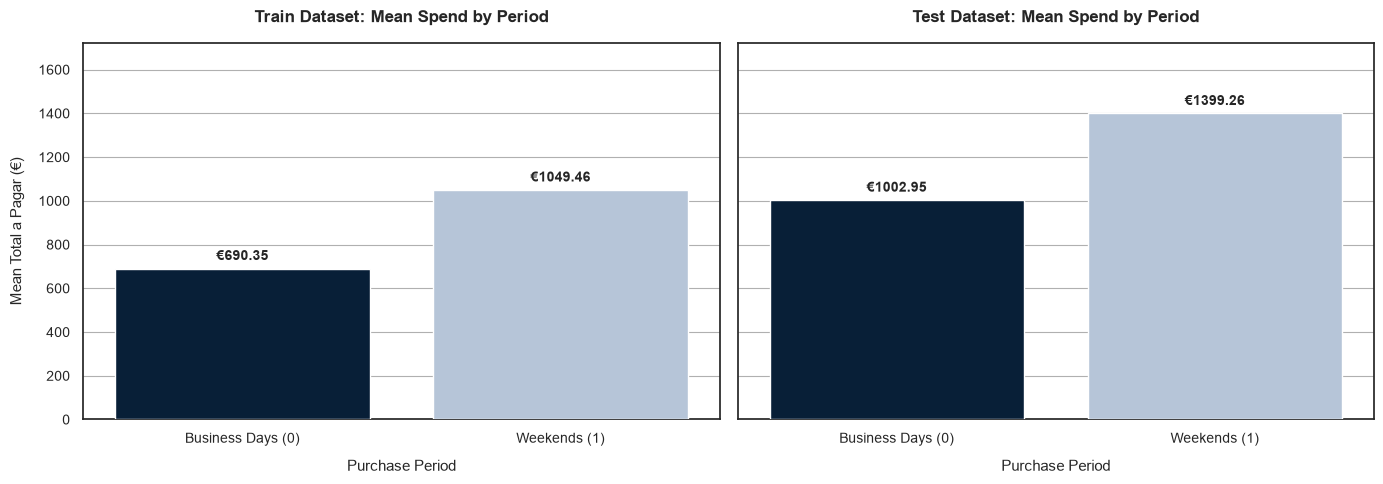

In [18]:

def plot_mean_transaction_value_comparison(df_train, df_test):
  # Prepare temporary copies with descriptive period labels
  train_fin = df_train.copy()
  train_fin['period_label'] = train_fin['is_weekend'].map(
      {0: 'Business Days (0)', 1: 'Weekends (1)'}
  )

  test_fin = df_test.copy()
  test_fin['period_label'] = test_fin['is_weekend'].map(
      {0: 'Business Days (0)', 1: 'Weekends (1)'}
  )

  # Configure figure with two side-by-side subplots
  fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
  sns.set_theme(style='white')

  # Data structure for iteration
  datasets = [(train_fin, 'Train Dataset', axes[0]), (test_fin, 'Test Dataset', axes[1])]

  for df_curr, title_prefix, ax in datasets:
    ax.set_axisbelow(True)
    ax.yaxis.grid(True, color='#b0b0b0', linestyle='-', linewidth=0.8, zorder=0)

    # Bar plot representing the mean 'Total a Pagar' by period
    sns.barplot(
        data=df_curr,
        x='period_label',
        y='Total a Pagar',
        order=['Business Days (0)', 'Weekends (1)'],
        palette=['#001f3f', '#b0c4de'],
        ax=ax,
        zorder=3,
        errorbar=None,
    )

    ax.set_title(
        f'{title_prefix}: Mean Spend by Period',
        fontsize=12,
        fontweight='bold',
        pad=15,
    )
    ax.set_xlabel('Purchase Period', fontsize=11, labelpad=10)
    ax.set_ylabel('Mean Total a Pagar (€)', fontsize=11, labelpad=10)
    ax.tick_params(labelsize=10)

    # Add exact monetary values on top of the bars
    for p in ax.patches:
      height = p.get_height()
      if height > 0:
        ax.annotate(
            f'€{height:.2f}',
            (p.get_x() + p.get_width() / 2.0, height),
            ha='center',
            va='bottom',
            xytext=(0, 4),
            textcoords='offset points',
            fontsize=10,
            fontweight='bold',
            zorder=4,
        )

    # Dynamically expand the y-axis limit by 25% for clean margin inside frame
    y_max = ax.get_ylim()[1]
    ax.set_ylim(0, y_max * 1.25)

  plt.tight_layout()
  plt.show()

# Run comparison between Train and Test
plot_mean_transaction_value_comparison(df_train_clean, df_test_clean)

**Conclusions:**
* **Weekend orders are larger:** In both sets, the mean transaction value (`Total a Pagar`) is clearly higher on weekends than on business days. In train it is €1,049.46 on weekends vs. €690.35 on business days (+€359, about +52%). In test it is €1,399.26 vs. €1,002.95 (+€396, about +40%).
* **Consistent direction:** The same ordering appears in train and test, so the weekend premium is not specific to one dataset. The size of the gap differs somewhat (+52% vs. +40%).
* **Revenue concentration:** Weekends have about two thirds of the transactions and a higher mean value per transaction. As a result, weekends probably account for roughly three quarters of the total revenue (an estimate based on the approximate counts of the previous plot).
* **Link with the repeat rate:** Weekend transactions have a higher value (this plot) but a lower 90-day repeat rate (51.5% vs. 64.4% on weekdays). Weekend orders are therefore bigger but less likely to be followed by a new purchase, while weekday orders are smaller but more recurrent. This suggests that `is_weekend` carries information about both the type of purchase and the type of customer.
* **Train vs. test difference:** The test set has higher mean values than the train set in both periods (about +45% on business days and +33% on weekends). This indicates a difference in the distribution of `Total a Pagar` between the two sets, which could affect model performance if the target is related to spend. It deserves a closer look at the full distributions.
* **Limits:** The plot shows means only, without error bars (`errorbar=None`), so it is not possible to tell whether the gaps are statistically significant. Means are also sensitive to extreme values, and this dataset already showed placeholder values in other monetary columns. Comparing medians, or a boxplot of `Total a Pagar` by period, would confirm that the difference is not driven by a few very large orders.
* **Predictive relevance:** The difference in spend supports keeping `is_weekend` as a candidate feature. Its added value on top of the spend features should be confirmed during modelling.

____________________________________________________________________________________________________________________________________________________________________________________

## 2.6. Final Audit of Residual Missing Values
The final files of this notebook (`train_2_5_1.csv` and `test_2_5_1.csv`) are checked for columns that still contain missing values.

In [19]:
inputFileTrain = "../../../data/trainDataset/train_2_5_1.csv"
inputFileTest = "../../../data/testDataset/test_2_5_1.csv"


def check_remaining_missing_values(input_file, dataset_label="Dataset"):
  # Load the dataset
  df = pd.read_csv(input_file)

  # Calculate total missing values per column and filter only those with > 0 nulls
  missing_counts = df.isnull().sum()
  missing_counts = missing_counts[missing_counts > 0]

  print(f"=== REMAINING MISSING VALUES ({dataset_label}) ===")
  if len(missing_counts) > 0:
    print(missing_counts)
    print(f"\nTotal columns with nulls: {len(missing_counts)}")
  else:
    print(
        f"Congratulations! There are no missing values left in the"
        f" {dataset_label} dataset."
    )
  print("-" * 50 + "\n")

  return missing_counts


# Run the check for Train and Test
missing_train = check_remaining_missing_values(
    inputFileTrain, dataset_label="Train"
)
missing_test = check_remaining_missing_values(
    inputFileTest, dataset_label="Test"
)

=== REMAINING MISSING VALUES (Train) ===
spend_365d          210
payment_type        195
salesperson         194
transport_method    196
warehouse           195
dtype: int64

Total columns with nulls: 5
--------------------------------------------------

=== REMAINING MISSING VALUES (Test) ===
spend_365d          32
payment_type        30
salesperson         30
transport_method    30
warehouse           30
dtype: int64

Total columns with nulls: 5
--------------------------------------------------



**Conclusion:** Five columns still contain missing values in both datasets, about 3% of the rows in each case:

| Column | Train | Test |
|---|---|---|
| `spend_365d` | 210 | 32 |
| `payment_type` | 195 | 30 |
| `salesperson` | 194 | 30 |
| `transport_method` | 196 | 30 |
| `warehouse` | 195 | 30 |

* **`spend_365d`:** these counts are identical to the `NaN` counts right after Section 2.1.2, so the values created by masking invalid negatives were not recovered in Section 2.4.2. Since this feature can be derived from `purchase_count_365d`, `prior_purchase_count` and `prior_total_spend`, it could be rebuilt with the logic of Section 2.4.2 instead of being imputed.
* **Categorical columns:** `payment_type`, `salesperson`, `transport_method` and `warehouse` are order-level attributes that this notebook does not treat. Because most models need complete feature matrices, they will be handled in the next notebook, by enriching the data from the clients table where possible and assigning an explicit `"Unknown"` category to the rest.

The cleaned files are the input of the next notebook, where the datasets are merged with the clients table and the remaining missing values are resolved.


---
**Next:** [Clients – Data Ingestion and Initial Inspection](../1_clients/1_DataIngestion&InitialInspection.ipynb)